TBD

## 1. Setup and loading

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

# Chart style: one blue for single-series charts, orange as the 2nd categorical slot,
# neutral ink for text and a recessive grid. Blue/orange pass the colour-validation
# checks (colour-blind separation and contrast) for a 2-series chart.
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e3e2de"
plt.rcParams.update({
    "figure.dpi": 110, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 10, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7, "axes.axisbelow": True,
    "legend.frameon": False,
})
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#eef4fc", BLUE, "#0f2f5e"])
thousands = FuncFormatter(lambda v, _: f"{v:,.0f}")
DAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

In [2]:
raw = pd.read_csv("trips.csv", dtype={"trip_id": "string", "taxi_id": "string"})
for c in ["trip_start_timestamp", "trip_end_timestamp"]:
    raw[c] = pd.to_datetime(raw[c])

assert len(raw) == 135_768, "unexpected row count"
assert raw["trip_id"].is_unique, "duplicate trip_id"
print(f"{len(raw):,} rows, {raw.shape[1]} columns")
print("Trip start range:", raw.trip_start_timestamp.min(), "->", raw.trip_start_timestamp.max())
print("Duplicate trip_id:", raw.trip_id.duplicated().sum(), "| fully duplicated rows:", raw.duplicated().sum())

135,768 rows, 23 columns
Trip start range: 2023-09-11 00:00:00 -> 2023-09-17 23:45:00
Duplicate trip_id: 0 | fully duplicated rows: 0


## 2. Data cleaning

Everything below is applied once, to one analysis set, which every later section uses. The steps are: check for missing values, check for implausible values, check that `trip_total` reconciles with its parts, then decide what to exclude.

### 2.1 Missing values

In [3]:
cols = ["trip_start_timestamp", "trip_end_timestamp", "trip_seconds", "trip_miles", "pickup_community_area",
        "fare", "tips", "tolls", "extras", "trip_total", "payment_type", "company", "taxi_id"]
miss = raw[cols].isna().sum().rename("missing").to_frame()
miss["pct"] = (miss.missing / len(raw) * 100).round(2)
display(miss[miss.missing > 0])

money = ["fare", "tips", "tolls", "extras", "trip_total"]
print("Rows with ALL five money columns missing:", raw[money].isna().all(axis=1).sum())
print("Rows with SOME but not all missing:      ", (raw[money].isna().any(axis=1) & ~raw[money].isna().all(axis=1)).sum())
print("Missing-money rows by payment type:\n", raw.loc[raw.trip_total.isna(), "payment_type"].value_counts().to_string())

,missing,pct
trip_end_timestamp,1,0.00
trip_seconds,33,0.02
pickup_community_area,3815,2.81
fare,324,0.24
tips,324,0.24
tolls,324,0.24
extras,324,0.24
trip_total,324,0.24


Rows with ALL five money columns missing: 324
Rows with SOME but not all missing:       0
Missing-money rows by payment type:
 payment_type
Cash           323
Credit Card      1


TBD

### 2.2 Implausible values

In [4]:
sec = raw.trip_seconds
# implied speed only for trips of at least 1 mile; seconds == 0 with miles > 0 counts as impossible
speed = np.where(sec > 0, raw.trip_miles / (sec / 3600), np.where(raw.trip_miles >= 1, np.inf, 0))
raw["speed_mph"] = speed

desc = raw[["trip_seconds", "trip_miles", "fare", "tips", "tolls", "extras", "trip_total"]].describe(
    percentiles=[.01, .5, .99]).T[["count", "min", "1%", "50%", "99%", "max"]]
display(desc.round(2))

checks = {
    "trip_total missing":                       raw.trip_total.isna(),
    "trip_total <= 0":                          raw.trip_total <= 0,
    "trip_total > $500":                        raw.trip_total > 500,
    "tolls > $50":                              raw.tolls > 50,
    "trip_seconds > 12 hours":                  raw.trip_seconds > 12 * 3600,
    "trip_miles > 100":                         raw.trip_miles > 100,
    "implied speed > 100 mph (trips >= 1 mile)": (raw.speed_mph > 100) & (raw.trip_miles >= 1),
}
retained = {
    "trip_miles == 0":                          raw.trip_miles == 0,
    "trip_seconds == 0":                        raw.trip_seconds == 0,
    "fare > $50 and trip_miles < 1 (flat-rate-looking)": (raw.fare > 50) & (raw.trip_miles < 1),
    "extras > $50":                             raw.extras > 50,
    "tips > fare":                              raw.tips > raw.fare,
}
tab = pd.DataFrame({"rows": {k: int(v.sum()) for k, v in {**checks, **retained}.items()}})
tab["pct of all rows"] = (tab.rows / len(raw) * 100).round(2)
tab["treatment"] = ["EXCLUDE"] * len(checks) + ["keep, flag only"] * len(retained)
display(tab)

,count,min,1%,50%,99%,max
trip_seconds,135735.0,0.0,0.00,1020.00,4872.98,86160.00
trip_miles,135768.0,0.0,0.00,3.24,27.14,792.90
fare,135444.0,0.0,3.25,17.75,75.50,911.00
tips,135444.0,0.0,0.00,2.00,17.10,130.00
tolls,135444.0,0.0,0.00,0.00,0.00,4444.44
extras,135444.0,0.0,0.00,0.00,35.50,4445.44
trip_total,135444.0,0.0,3.25,21.25,104.43,8901.13


,rows,pct of all rows,treatment
trip_total missing,324,0.24,EXCLUDE
trip_total <= 0,134,0.10,EXCLUDE
trip_total > $500,8,0.01,EXCLUDE
tolls > $50,6,0.00,EXCLUDE
trip_seconds > 12 hours,61,0.04,EXCLUDE
trip_miles > 100,11,0.01,EXCLUDE
implied speed > 100 mph (trips >= 1 mile),94,0.07,EXCLUDE
trip_miles == 0,13993,10.31,"keep, flag only"
trip_seconds == 0,2731,2.01,"keep, flag only"
fare > $50 and trip_miles < 1 (flat-rate-looking),1815,1.34,"keep, flag only"


TBD

### 2.3 Does `trip_total` equal fare + tips + tolls + extras?

In [5]:
raw["parts"] = raw[["fare", "tips", "tolls", "extras"]].sum(axis=1, min_count=4)
raw["gap"] = (raw.trip_total - raw.parts).round(2)

def gap_class(g):
    if pd.isna(g): return "n/a (missing)"
    if abs(g) < 0.005: return "matches"
    if abs(g - 0.50) < 0.005: return "+$0.50"
    if g in (2.5, 3.0): return "+$2.50 or +$3.00"
    return "other"
raw["gap_class"] = raw.gap.map(gap_class)

print("Distribution of (trip_total - sum of parts):")
display(raw.gap.value_counts().head(8).rename("trips").to_frame())
g = raw[raw.gap_class != "n/a (missing)"]
display(pd.crosstab(g.gap_class, g.payment_type, margins=True))
print("Largest absolute gap:", raw.gap.abs().max(), "| trips with a negative gap:", (raw.gap < 0).sum())
print(f"Mismatching rows (all): {(raw.gap.abs() > 0.005).sum():,} = {(raw.gap.abs() > 0.005).mean():.1%} of all rows")

Distribution of (trip_total - sum of parts):


,trips
gap,
0.00,87247
0.50,46522
3.00,804
2.50,751
1.00,109
1.95,5
1.50,4
2.00,2


payment_type,Cash,Credit Card,Dispute,Mobile,No Charge,Prcard,Unknown,All
gap_class,,,,,,,,
+$0.50,3,42409,0,4110,0,0,0,46522
+$2.50 or +$3.00,675,806,0,57,0,17,0,1555
matches,39052,16962,31,14420,54,11944,4784,87247
other,0,113,0,7,0,0,0,120
All,39730,60290,31,18594,54,11961,4784,135444


Largest absolute gap: 3.0 | trips with a negative gap: 0
Mismatching rows (all): 48,197 = 35.5% of all rows


TBD

### 2.4 Cleaning decisions applied

In [6]:
# Standardise company names: two obvious spelling variants of the same company.
company_map = {
    "Taxicab Insurance Agency, LLC": "Taxicab Insurance Agency Llc",
    "Choice Taxi Association Inc":   "Choice Taxi Association",
}
print("Company names before:", raw.company.nunique(), "| after mapping:", raw.company.replace(company_map).nunique())

# Sequential exclusion waterfall: each row is counted under the first rule it fails.
removed = pd.Series(False, index=raw.index)
rows = []
for name, mask in checks.items():
    new = mask & ~removed
    removed |= mask
    rows.append((name, int(new.sum()), int(removed.sum())))
wf = pd.DataFrame(rows, columns=["rule (in order)", "newly excluded rows", "cumulative excluded"])
display(wf)

df = raw.loc[~removed].copy()
df["company"] = df.company.replace(company_map)
df["start"] = df.trip_start_timestamp
df["date"] = df.start.dt.normalize()
df["dow"] = df.start.dt.day_of_week                   # 0 = Monday
df["day"] = df.dow.map(dict(enumerate(DAYS)))
df["hour"] = df.start.dt.hour
df["is_weekend"] = df.dow >= 5
print(f"\nAnalysis set: {len(df):,} trips ({len(df)/len(raw):.2%} of {len(raw):,}); excluded {removed.sum():,} ({removed.mean():.2%})")

Company names before: 32 | after mapping: 30


,rule (in order),newly excluded rows,cumulative excluded
0,trip_total missing,324,324
1,trip_total <= 0,134,458
2,trip_total > $500,8,466
3,tolls > $50,3,469
4,trip_seconds > 12 hours,60,529
5,trip_miles > 100,11,540
6,implied speed > 100 mph (trips >= 1 mile),89,629



Analysis set: 135,139 trips (99.54% of 135,768); excluded 629 (0.46%)


TBD

### 2.5 Sensitivity check: do the exclusions change the story?

In [7]:
def headline(d):
    return pd.Series({
        "trips": len(d),
        "busiest day": d.trip_start_timestamp.dt.day_name().value_counts().idxmax(),
        "busiest hour": int(d.trip_start_timestamp.dt.hour.value_counts().idxmax()),
        "top pickup area (count)": int(d.pickup_community_area.value_counts().idxmax()),
        "no pickup area %": round(d.pickup_community_area.isna().mean() * 100, 2),
        "top payment type": d.payment_type.value_counts().idxmax(),
        "top company": d.company.replace(company_map).value_counts().idxmax(),
        "top-10 company share %": round(d.company.replace(company_map).value_counts().head(10).sum() / len(d) * 100, 1),
    })
display(pd.DataFrame({"raw (135,768)": headline(raw), "analysis set": headline(df)}))

,"raw (135,768)",analysis set
trips,135768,135139
busiest day,Wednesday,Wednesday
busiest hour,17,17
top pickup area (count),76,76
no pickup area %,2.81,2.8
top payment type,Credit Card,Credit Card
top company,Flash Cab,Flash Cab
top-10 company share %,92.2,92.2


TBD

## 3. Q1 — When is demand highest?

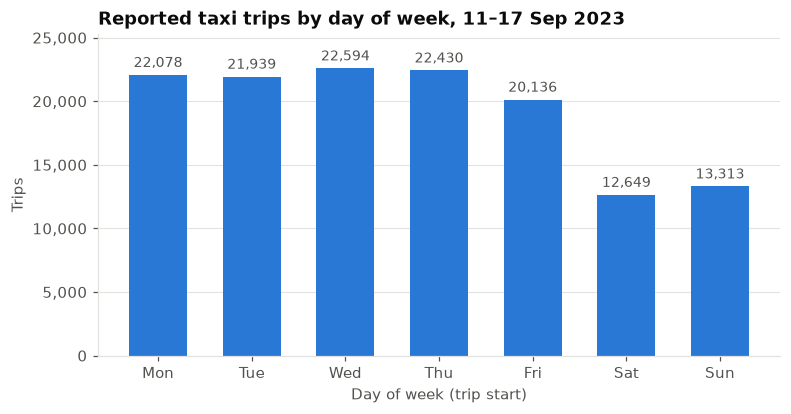

,Mon,Tue,Wed,Thu,Fri,Sat,Sun
trips,22078,21939,22594,22430,20136,12649,13313
vs Mon–Thu avg,-1%,-1%,+1%,+1%,-10%,-43%,-40%


Mon–Fri average per day: 21,835 | Sat–Sun average per day: 12,981 | weekend/weekday = 59%


In [8]:
by_day = df.groupby("dow").size().reindex(range(7))
by_day.index = DAYS

fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.bar(by_day.index, by_day.values, color=BLUE, width=0.62)
ax.bar_label(bars, labels=[f"{v:,}" for v in by_day.values], padding=3, color=INK2, fontsize=9)
ax.set_title("Reported taxi trips by day of week, 11–17 Sep 2023")
ax.set_xlabel("Day of week (trip start)"); ax.set_ylabel("Trips")
ax.yaxis.set_major_formatter(thousands); ax.set_ylim(0, by_day.max() * 1.12); ax.grid(axis="x", visible=False)
plt.show()

d = by_day.to_frame("trips")
d["vs Mon–Thu avg"] = (d.trips / by_day.iloc[:4].mean() - 1).map("{:+.0%}".format)
display(d.T)
wk, we = df[~df.is_weekend], df[df.is_weekend]
print(f"Mon–Fri average per day: {len(wk)/5:,.0f} | Sat–Sun average per day: {len(we)/2:,.0f} "
      f"| weekend/weekday = {(len(we)/2)/(len(wk)/5):.0%}")

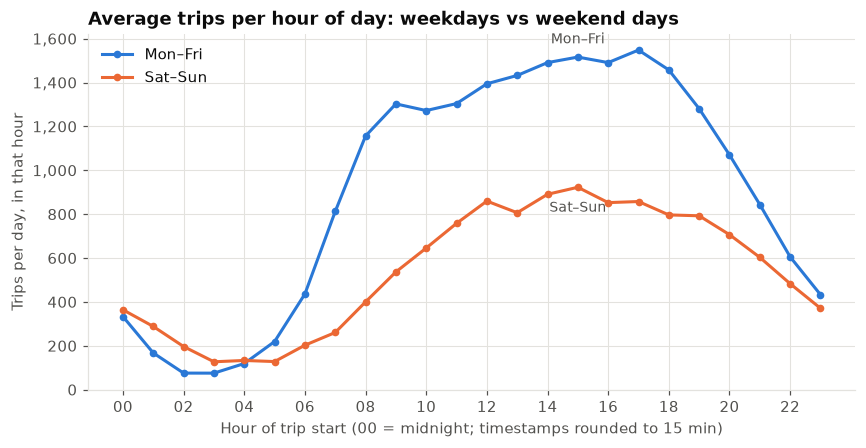

In [9]:
# Average trips per hour of day: weekday days (Mon-Fri, 5 days) vs weekend days (Sat-Sun, 2 days)
hr = pd.DataFrame({
    "Mon–Fri (avg per day)": df[~df.is_weekend].groupby("hour").size() / 5,
    "Sat–Sun (avg per day)": df[df.is_weekend].groupby("hour").size() / 2,
}).reindex(range(24)).fillna(0)
hr["all week (total)"] = df.groupby("hour").size().reindex(range(24)).fillna(0).astype(int)

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(hr.index, hr.iloc[:, 0], color=BLUE, lw=2, marker="o", ms=4, label="Mon–Fri")
ax.plot(hr.index, hr.iloc[:, 1], color=ORANGE, lw=2, marker="o", ms=4, label="Sat–Sun")
ax.annotate("Mon–Fri", (hr.index[15], hr.iloc[15, 0]), xytext=(0, 9), textcoords="offset points", color=INK2, ha="center", fontsize=9)
ax.annotate("Sat–Sun", (hr.index[15], hr.iloc[15, 1]), xytext=(0, -16), textcoords="offset points", color=INK2, ha="center", fontsize=9)
ax.set_xticks(range(0, 24, 2)); ax.set_xticklabels([f"{h:02d}" for h in range(0, 24, 2)])
ax.set_title("Average trips per hour of day: weekdays vs weekend days")
ax.set_xlabel("Hour of trip start (00 = midnight; timestamps rounded to 15 min)"); ax.set_ylabel("Trips per day, in that hour")
ax.yaxis.set_major_formatter(thousands); ax.set_ylim(0); ax.legend(loc="upper left")
plt.show()

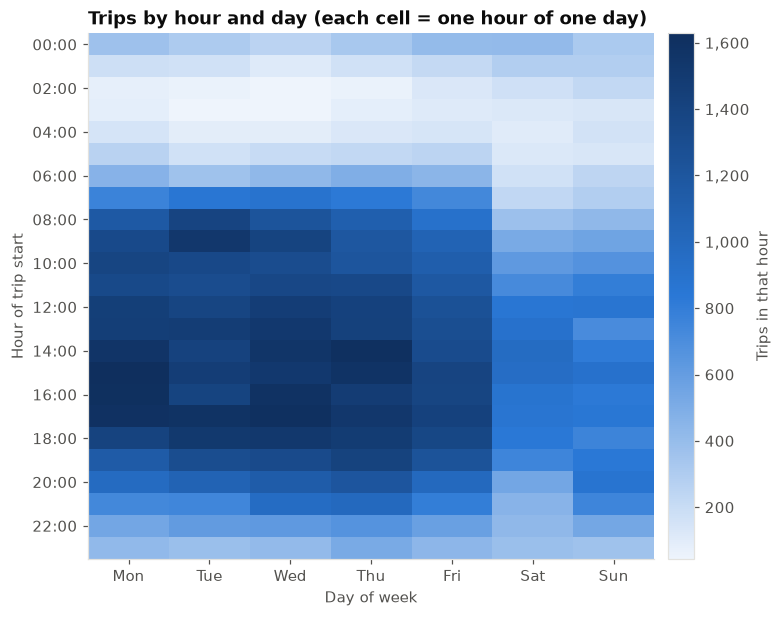

Busiest 5 day-hours:  Mon 15:00 (1,628), Mon 16:00 (1,611), Thu 14:00 (1,607), Wed 17:00 (1,607), Mon 17:00 (1,596)
Quietest 5 day-hours: Wed 03:00 (45), Tue 03:00 (46), Wed 02:00 (51), Thu 02:00 (61), Tue 02:00 (63)
Busiest 3 hours of day (all week): 17:00 (9,455), 15:00 (9,425), 14:00 (9,235)
Quietest 3 hours of day (all week): 03:00 (630), 02:00 (770), 04:00 (861)


hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
Mon–Fri (avg per day),333,167,75,75,119,219,436,812,1156,1303,1272,1304,1394,1432,1491,1516,1491,1548,1457,1281,1070,844,605,433
Sat–Sun (avg per day),364,288,196,127,133,128,202,260,400,536,646,758,860,806,890,922,852,858,796,792,706,603,483,371
all week (total),2393,1412,770,630,861,1352,2586,4583,6582,7586,7652,8036,8690,8774,9235,9425,9159,9455,8880,7989,6764,5425,3993,2907


In [10]:
grid = df.groupby(["hour", "dow"]).size().unstack("dow").reindex(index=range(24), columns=range(7)).fillna(0)
fig, ax = plt.subplots(figsize=(8, 6.2))
im = ax.imshow(grid.values, aspect="auto", cmap=SEQ, origin="upper")
ax.set_xticks(range(7)); ax.set_xticklabels(DAYS); ax.set_yticks(range(0, 24, 2)); ax.set_yticklabels([f"{h:02d}:00" for h in range(0, 24, 2)])
ax.grid(False)
ax.set_title("Trips by hour and day (each cell = one hour of one day)")
ax.set_xlabel("Day of week"); ax.set_ylabel("Hour of trip start")
cb = fig.colorbar(im, ax=ax, pad=0.02); cb.set_label("Trips in that hour"); cb.ax.yaxis.set_major_formatter(thousands)
plt.show()

cell = grid.stack(); cell.index = [f"{DAYS[d]} {h:02d}:00" for h, d in cell.index]
print("Busiest 5 day-hours: ", ", ".join(f"{k} ({v:,.0f})" for k, v in cell.nlargest(5).items()))
print("Quietest 5 day-hours:", ", ".join(f"{k} ({v:,.0f})" for k, v in cell.nsmallest(5).items()))
tot = hr["all week (total)"]
print("Busiest 3 hours of day (all week):", ", ".join(f"{h:02d}:00 ({tot[h]:,})" for h in tot.nlargest(3).index))
print("Quietest 3 hours of day (all week):", ", ".join(f"{h:02d}:00 ({tot[h]:,})" for h in tot.nsmallest(3).index))
display(hr.round(0).astype(int).T)

TBD

## 4. Q2 — Where do trips start?

In [11]:
n = len(df)
no_area = df.pickup_community_area.isna()
print(f"Trips with no pickup community area: {no_area.sum():,} = {no_area.mean():.2%} of {n:,} analysis trips "
      f"({raw.pickup_community_area.isna().mean():.2%} of all {len(raw):,} raw rows)")
print("Of those, pickup lat/long also blank:", f"{df.loc[no_area, 'pickup_centroid_latitude'].isna().mean():.1%}")
print("Trip_total in no-area trips:", f"${df.loc[no_area, 'trip_total'].sum():,.0f} ({df.loc[no_area,'trip_total'].sum()/df.trip_total.sum():.1%} of revenue)")

area = (df.dropna(subset=["pickup_community_area"]).assign(area=lambda x: x.pickup_community_area.astype(int))
          .groupby("area").agg(trips=("trip_id", "size"), revenue=("trip_total", "sum")))
area["share of all trips"] = area.trips / n
area["share of revenue"] = area.revenue / df.trip_total.sum()
area["avg trip_total"] = area.revenue / area.trips

top_n = area.sort_values("trips", ascending=False).head(10)
top_r = area.sort_values("revenue", ascending=False).head(10)

fmt = {"trips": "{:,.0f}", "revenue": "${:,.0f}", "share of all trips": "{:.1%}", "share of revenue": "{:.1%}", "avg trip_total": "${:,.2f}"}
print("\nTop 10 pickup community areas by trip count")
display(top_n.style.format(fmt))
print("Top 10 pickup community areas by total trip_total")
display(top_r.style.format(fmt))
print(f"Top 10 by count hold {top_n.trips.sum()/n:.1%} of all trips; top 3 hold {top_n.trips.head(3).sum()/n:.1%}.")
print(f"Top 10 by revenue hold {top_r.revenue.sum()/df.trip_total.sum():.1%} of all revenue.")
print("Areas in top 10 by one list only:", sorted(set(top_n.index) ^ set(top_r.index)))

Trips with no pickup community area: 3,781 = 2.80% of 135,139 analysis trips (2.81% of all 135,768 raw rows)
Of those, pickup lat/long also blank: 98.9%
Trip_total in no-area trips: $139,550 (3.4% of revenue)

Top 10 pickup community areas by trip count


,trips,revenue,share of all trips,share of revenue,avg trip_total
area,,,,,
76,"31,530","$1,728,711",23.3%,42.7%,$54.83
8,"28,191","$517,248",20.9%,12.8%,$18.35
32,"22,055","$420,864",16.3%,10.4%,$19.08
28,"11,243","$185,528",8.3%,4.6%,$16.50
33,"6,671","$172,110",4.9%,4.3%,$25.80
56,"5,402","$252,542",4.0%,6.2%,$46.75
6,"3,920","$78,041",2.9%,1.9%,$19.91
7,"2,532","$48,798",1.9%,1.2%,$19.27
3,"1,914","$39,468",1.4%,1.0%,$20.62


Top 10 pickup community areas by total trip_total


,trips,revenue,share of all trips,share of revenue,avg trip_total
area,,,,,
76,"31,530","$1,728,711",23.3%,42.7%,$54.83
8,"28,191","$517,248",20.9%,12.8%,$18.35
32,"22,055","$420,864",16.3%,10.4%,$19.08
56,"5,402","$252,542",4.0%,6.2%,$46.75
28,"11,243","$185,528",8.3%,4.6%,$16.50
33,"6,671","$172,110",4.9%,4.3%,$25.80
6,"3,920","$78,041",2.9%,1.9%,$19.91
7,"2,532","$48,798",1.9%,1.2%,$19.27
3,"1,914","$39,468",1.4%,1.0%,$20.62


Top 10 by count hold 85.1% of all trips; top 3 hold 60.5%.
Top 10 by revenue hold 86.0% of all revenue.
Areas in top 10 by one list only: []


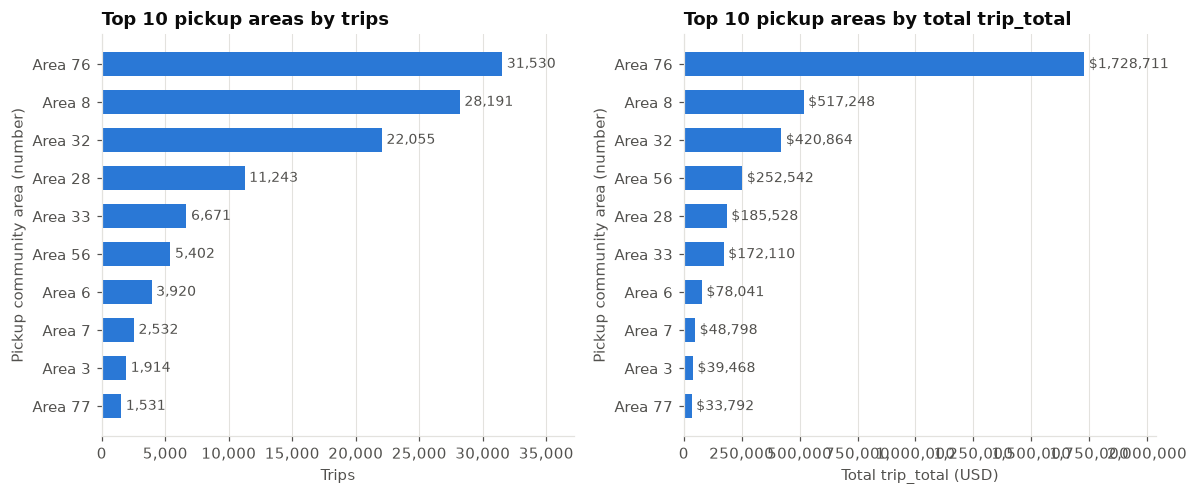

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, tbl, col, ttl, xl in [
    (axes[0], top_n, "trips", "Top 10 pickup areas by trips", "Trips"),
    (axes[1], top_r, "revenue", "Top 10 pickup areas by total trip_total", "Total trip_total (USD)"),
]:
    s = tbl[col][::-1]
    b = ax.barh([f"Area {a}" for a in s.index], s.values, color=BLUE, height=0.62)
    lab = [f"{v:,.0f}" if col == "trips" else f"${v:,.0f}" for v in s.values]
    ax.bar_label(b, labels=lab, padding=3, color=INK2, fontsize=9)
    ax.set_title(ttl); ax.set_xlabel(xl); ax.set_ylabel("Pickup community area (number)")
    ax.set_xlim(0, s.max() * 1.18); ax.xaxis.set_major_formatter(thousands); ax.grid(axis="y", visible=False)
fig.tight_layout(); plt.show()

TBD

## 5. Q3 — How do riders pay and tip?

In [13]:
def pay_summary(d):
    g = d.groupby("payment_type")
    out = pd.DataFrame({
        "trips": g.size(),
        "share of trips": g.size() / len(d),
        "total revenue (sum trip_total)": g.trip_total.sum(),
        "avg fare": g.fare.mean(),
        "total fare": g.fare.sum(),
        "total tips": g.tips.sum(),
    })
    out["tips % of fare (sum tips / sum fare)"] = out["total tips"] / out["total fare"] * 100
    pos = d[d.fare > 0].assign(tip_pct=lambda x: x.tips / x.fare * 100)
    out["median per-trip tip %"] = pos.groupby("payment_type").tip_pct.median()
    out["% trips with a tip > 0"] = d.assign(t=d.tips > 0).groupby("payment_type").t.mean() * 100
    return out.sort_values("trips", ascending=False)

pay = pay_summary(df)
tot_row = pd.DataFrame({
    "trips": [len(df)], "share of trips": [1.0], "total revenue (sum trip_total)": [df.trip_total.sum()],
    "avg fare": [df.fare.mean()], "total fare": [df.fare.sum()], "total tips": [df.tips.sum()],
    "tips % of fare (sum tips / sum fare)": [df.tips.sum() / df.fare.sum() * 100],
    "median per-trip tip %": [np.nan], "% trips with a tip > 0": [(df.tips > 0).mean() * 100]}, index=["All trips"])
pay_show = pd.concat([pay, tot_row])
display(pay_show.drop(columns=["total fare", "total tips"]).style.format({
    "trips": "{:,.0f}", "share of trips": "{:.1%}", "total revenue (sum trip_total)": "${:,.0f}", "avg fare": "${:,.2f}",
    "tips % of fare (sum tips / sum fare)": "{:.1f}%", "median per-trip tip %": "{:.1f}%", "% trips with a tip > 0": "{:.1f}%"}, na_rep="–"))

,trips,share of trips,total revenue (sum trip_total),avg fare,tips % of fare (sum tips / sum fare),median per-trip tip %,% trips with a tip > 0
Credit Card,"60,254",44.6%,"$2,417,724",$29.01,22.1%,22.6%,93.6%
Cash,"39,482",29.2%,"$788,291",$18.30,0.1%,0.0%,0.4%
Mobile,"18,594",13.8%,"$413,943",$17.81,20.5%,22.2%,92.7%
Prcard,"11,945",8.8%,"$306,986",$25.42,0.7%,0.0%,5.2%
Unknown,"4,783",3.5%,"$115,614",$24.04,0.0%,0.0%,0.1%
No Charge,50,0.0%,"$2,143",$36.14,1.9%,0.0%,8.0%
Dispute,31,0.0%,$752,$21.31,0.0%,0.0%,0.0%
All trips,"135,139",100.0%,"$4,045,453",$23.85,14.2%,–,55.1%


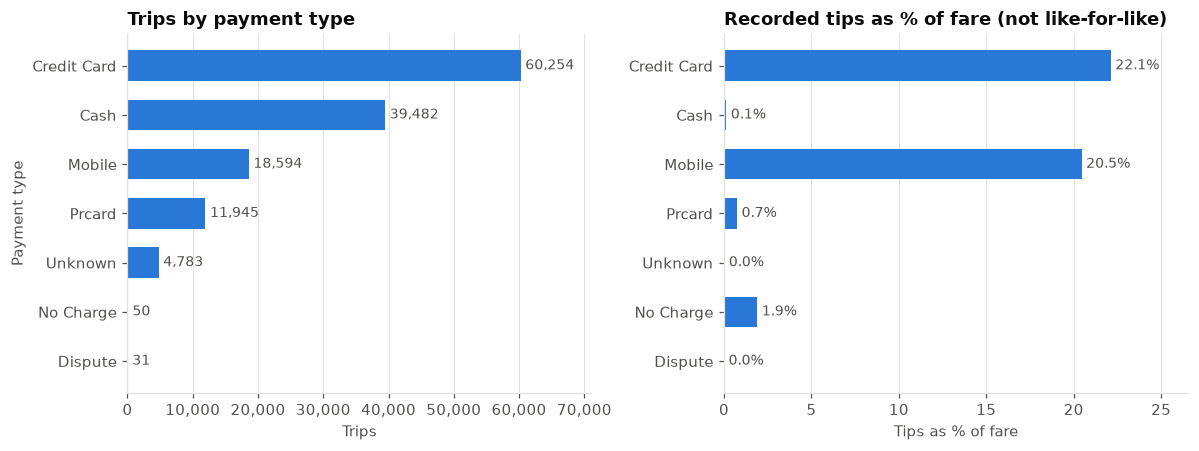

Credit Card and Mobile trips only (tips recorded), per-trip tip % of fare (percentiles; a few extreme per-trip values exist, e.g. a $0.01 fare, so means are not shown):


,p10,p25,p50,p75,p90,trips
payment_type,,,,,,
Credit Card,11.1,20.2,22.6,29.6,41.7,60254
Mobile,9.4,17.0,22.2,25.4,28.7,18594


,mean fare,median fare,median miles
payment_type,,,
Credit Card,29.01,30.50,5.51
Mobile,17.81,11.12,2.27


Prcard / Unknown / Cash tip-recorded trips: {'Prcard': 619, 'Unknown': 7, 'Cash': 158}


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
p = pay.trips[::-1]
b = axes[0].barh(p.index, p.values, color=BLUE, height=0.62)
axes[0].bar_label(b, labels=[f"{v:,}" for v in p.values], padding=3, color=INK2, fontsize=9)
axes[0].set_title("Trips by payment type"); axes[0].set_xlabel("Trips"); axes[0].set_ylabel("Payment type")
axes[0].set_xlim(0, p.max() * 1.18); axes[0].xaxis.set_major_formatter(thousands); axes[0].grid(axis="y", visible=False)

tp = pay["tips % of fare (sum tips / sum fare)"][::-1]
b = axes[1].barh(tp.index, tp.values, color=BLUE, height=0.62)
axes[1].bar_label(b, labels=[f"{v:.1f}%" for v in tp.values], padding=3, color=INK2, fontsize=9)
axes[1].set_title("Recorded tips as % of fare (not like-for-like)"); axes[1].set_xlabel("Tips as % of fare"); axes[1].set_ylabel("")
axes[1].set_xlim(0, tp.max() * 1.2); axes[1].grid(axis="y", visible=False)
fig.tight_layout(); plt.show()

# Electronic payments only (where tips are recorded): tip % distribution
card = df[df.payment_type.isin(["Credit Card", "Mobile"]) & (df.fare > 0)].assign(tip_pct=lambda x: x.tips / x.fare * 100)
print("Credit Card and Mobile trips only (tips recorded), per-trip tip % of fare (percentiles; a few extreme per-trip values exist, e.g. a $0.01 fare, so means are not shown):")
display(card.groupby("payment_type").tip_pct.quantile([.1, .25, .5, .75, .9]).unstack().round(1).rename(columns=lambda q: f"p{int(q*100)}").assign(trips=card.groupby("payment_type").size()))
display(card.groupby("payment_type").agg(**{"mean fare": ("fare", "mean"), "median fare": ("fare", "median"),
        "median miles": ("trip_miles", "median")}).round(2))
print("Prcard / Unknown / Cash tip-recorded trips:", {k: int((df[df.payment_type == k].tips > 0).sum()) for k in ["Prcard", "Unknown", "Cash"]})

TBD

## 6. Q4 — Which companies carry the trips?

In [15]:
g = df.groupby("company")
comp = pd.DataFrame({
    "trips": g.size(),
    "total revenue": g.trip_total.sum(),
    "distinct taxis": g.taxi_id.nunique(),
})
comp["share of all trips"] = comp.trips / len(df)
comp["trips per taxi"] = comp.trips / comp["distinct taxis"]
top_c = comp.sort_values("trips", ascending=False).head(10)[["trips", "share of all trips", "total revenue", "distinct taxis", "trips per taxi"]]
top_c.index.name = "company"
display(top_c.style.format({"trips": "{:,.0f}", "share of all trips": "{:.1%}", "total revenue": "${:,.0f}",
                            "distinct taxis": "{:,.0f}", "trips per taxi": "{:.1f}"}))
print(f"Top 10 companies: {top_c.trips.sum():,} trips = {top_c.trips.sum()/len(df):.1%} of all trips, "
      f"{top_c['total revenue'].sum()/df.trip_total.sum():.1%} of revenue. Companies in total: {df.company.nunique()}.")
print(f"Distinct taxis in whole week: {df.taxi_id.nunique():,} | sum of per-company counts: {comp['distinct taxis'].sum():,} "
      f"(taxis reported under more than one company: {(df.groupby('taxi_id').company.nunique() > 1).sum()})")
print("Top-2 share:", f"{top_c.trips.head(2).sum()/len(df):.1%}", "| Top-5 share:", f"{top_c.trips.head(5).sum()/len(df):.1%}")

,trips,share of all trips,total revenue,distinct taxis,trips per taxi
company,,,,,
Flash Cab,"25,838",19.1%,"$683,086",401,64.4
Taxi Affiliation Services,"25,651",19.0%,"$729,277",457,56.1
Taxicab Insurance Agency Llc,"16,150",12.0%,"$524,588",356,45.4
Sun Taxi,"15,062",11.1%,"$483,278",299,50.4
City Service,"13,648",10.1%,"$421,601",265,51.5
Chicago Independents,"7,956",5.9%,"$262,088",189,42.1
5 Star Taxi,"6,110",4.5%,"$210,000",140,43.6
Medallion Leasin,"4,996",3.7%,"$154,015",98,51.0
Globe Taxi,"4,746",3.5%,"$140,609",104,45.6


Top 10 companies: 124,540 trips = 92.2% of all trips, 92.1% of revenue. Companies in total: 30.
Distinct taxis in whole week: 2,656 | sum of per-company counts: 2,659 (taxis reported under more than one company: 3)
Top-2 share: 38.1% | Top-5 share: 71.3%


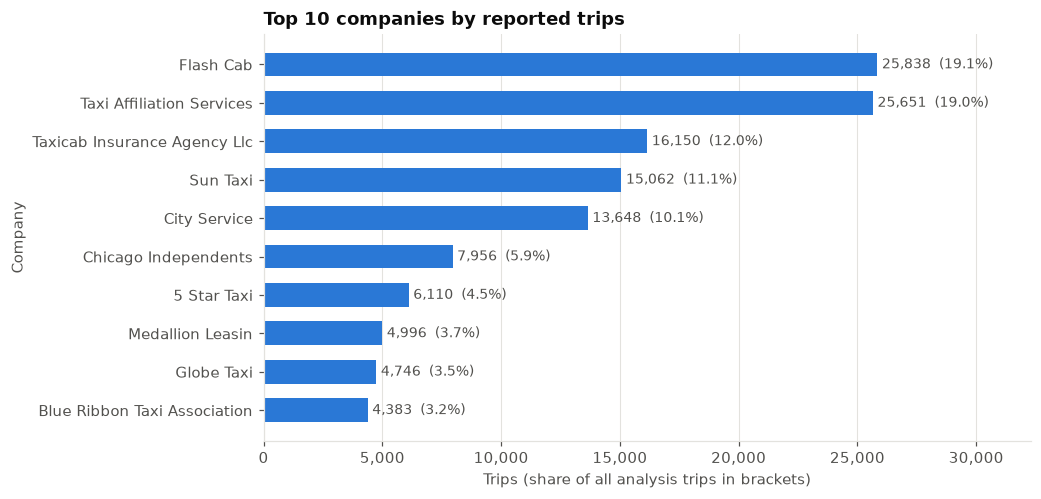

In [16]:
s = top_c.trips[::-1]
fig, ax = plt.subplots(figsize=(9, 4.8))
b = ax.barh(s.index, s.values, color=BLUE, height=0.62)
ax.bar_label(b, labels=[f"{v:,}  ({v/len(df):.1%})" for v in s.values], padding=3, color=INK2, fontsize=9)
ax.set_title("Top 10 companies by reported trips"); ax.set_xlabel("Trips (share of all analysis trips in brackets)"); ax.set_ylabel("Company")
ax.set_xlim(0, s.max() * 1.25); ax.xaxis.set_major_formatter(thousands); ax.grid(axis="y", visible=False)
plt.show()

TBD

TBD